# BIOT 6900 · Module 10 Assignment — Medical Imaging AI: Build It, Then Break It
### Computational Lab 10 · Graded Notebook (3 of 3) · Fall 2026
**Student:** Sharath Mandula

**The question:** not "can I get high accuracy?" — but **can I prove whether to believe it?**

| Part | What this notebook does |
|---|---|
| **A** | Fine-tune an ImageNet-pretrained DenseNet121 on PathMNIST tumour vs. normal; report validation + test accuracy (the clean baseline and later the clean control) |
| **B** | Probe the clean model with Grad-CAM **and** occlusion; apply the five-point skeptic's checklist with measured numbers |
| **C** | Design my own confounder — a **scanner/slide-label tag** — inject it into the tumour class (train + val) and retrain |
| **D** | Prove whether it was learned: heatmaps, reliance test, flip rate, all run on **both** models (clean control vs. confounded) |
| **E** | Written up separately in the PDF report in this folder |

**How to run:** put `pathmnist_tumour_vs_normal_subset.npz` in a `data/` folder next to this notebook, then **Kernel → Restart & Run All** (≈5–8 min on a laptop CPU). Figures are saved to `figures/` and all numbers to `results/module10_results.csv`.

## 0 · Setup

In [1]:
# Environment: conda env "biot6900"
# pip install torch torchvision --index-url https://download.pytorch.org/whl/cpu
# pip install "monai[pillow]" "medmnist>=3.0" scikit-learn matplotlib

import os, csv, numpy as np, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as Fnn

import monai
from monai.utils import set_determinism
from monai.networks.nets import DenseNet121
from monai.visualize import GradCAM

print("MONAI:", monai.__version__, "| torch:", torch.__version__)

SEED = 0
set_determinism(seed=SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

FIG_DIR, RES_DIR = "figures", "results"
os.makedirs(FIG_DIR, exist_ok=True); os.makedirs(RES_DIR, exist_ok=True)
def savefig(name):
    plt.savefig(os.path.join(FIG_DIR, name), dpi=150, bbox_inches="tight")

RESULTS = {}   # every reported number is collected here and written to results/ at the end

MONAI: 1.6.2 | torch: 2.15.0+cpu
device: cpu


## 1 · Data: PathMNIST tumour vs. normal (same subset as Notebook 2)
Normal colon mucosa → label `0`; colorectal adenocarcinoma epithelium → label `1`. Loaded from the provided subset file (no download).

In [2]:
from medmnist import PathMNIST, INFO

IMG_SIZE = 128        # size the model sees (GPU: try 224 — matches ImageNet pretraining, sharper Grad-CAM)
SUBSET_FILE = "./data/pathmnist_tumour_vs_normal_subset.npz"   # small prepared file (~60 MB), if you have it
DL_SIZE = 64          # only used if SUBSET_FILE is missing. PathMNIST download sizes:
                      #   28 px ~0.2 GB | 64 px ~1.1 GB | 128 px ~4.3 GB  (tiles are resized to IMG_SIZE either way)

print("PathMNIST classes:")
for k, v in INFO["pathmnist"]["label"].items():
    print(f"  {k}: {v}")

NORMAL, TUMOR = 6, 8                 # class ids in PathMNIST
class_names = ["normal", "tumour"]

def to_binary(x, y):
    keep = np.isin(y, [NORMAL, TUMOR])
    x, y = x[keep], y[keep]
    yb = (y == TUMOR).astype(np.int64)   # 1 = tumour, 0 = normal
    return x, yb

FROM_SUBSET = os.path.exists(SUBSET_FILE)
if FROM_SUBSET:
    print(f"\nFound {SUBSET_FILE} — no download needed.")
else:
    # medmnist returns images as HxWx3 uint8 and labels as (N,1)
    def load_split(split):
        ds = PathMNIST(split=split, download=True, size=DL_SIZE)
        return ds.imgs, ds.labels.squeeze()
    xtr, ytr = to_binary(*load_split("train"))
    xva, yva = to_binary(*load_split("val"))
    xte, yte = to_binary(*load_split("test"))
    print(f"\nbinary pools -> train {len(ytr)} | val {len(yva)} | test {len(yte)}")

PathMNIST classes:
  0: adipose
  1: background
  2: debris
  3: lymphocytes
  4: mucus
  5: smooth muscle
  6: normal colon mucosa
  7: cancer-associated stroma
  8: colorectal adenocarcinoma epithelium

Found ./data/pathmnist_tumour_vs_normal_subset.npz — no download needed.


In [3]:
N_PER_CLASS = 300    # GPU: raise to 1500+ for cleaner accuracy (delete SUBSET_FILE first so it is rebuilt)
rng = np.random.default_rng(SEED)

def subsample(x, y, n_per_class):
    idx = []
    for c in (0, 1):
        ci = np.where(y == c)[0]
        idx.append(rng.permutation(ci)[:n_per_class])
    idx = rng.permutation(np.concatenate(idx))
    return x[idx], y[idx]

if FROM_SUBSET:
    d = np.load(SUBSET_FILE)
    xtr_s, ytr_s, xva_s, yva_s, xte_s, yte_s = (d[k] for k in
        ["xtr", "ytr", "xva", "yva", "xte", "yte"])
    print(f"subset tiles are {xtr_s.shape[1]} px (resized to {IMG_SIZE} px below)")
else:
    xtr_s, ytr_s = subsample(xtr, ytr, N_PER_CLASS)
    xva_s, yva_s = subsample(xva, yva, min(200, (yva == 0).sum(), (yva == 1).sum()))
    xte_s, yte_s = subsample(xte, yte, min(300, (yte == 0).sum(), (yte == 1).sum()))
    os.makedirs(os.path.dirname(SUBSET_FILE), exist_ok=True)
    np.savez_compressed(SUBSET_FILE, xtr=xtr_s, ytr=ytr_s, xva=xva_s, yva=yva_s, xte=xte_s, yte=yte_s)
    del xtr, ytr, xva, yva, xte, yte          # free the large pools
    print(f"saved the subset to {SUBSET_FILE} — the next run skips the download")
print(f"using -> train {len(ytr_s)} | val {len(yva_s)} | test {len(yte_s)}")

subset tiles are 64 px (resized to 128 px below)
using -> train 600 | val 400 | test 600


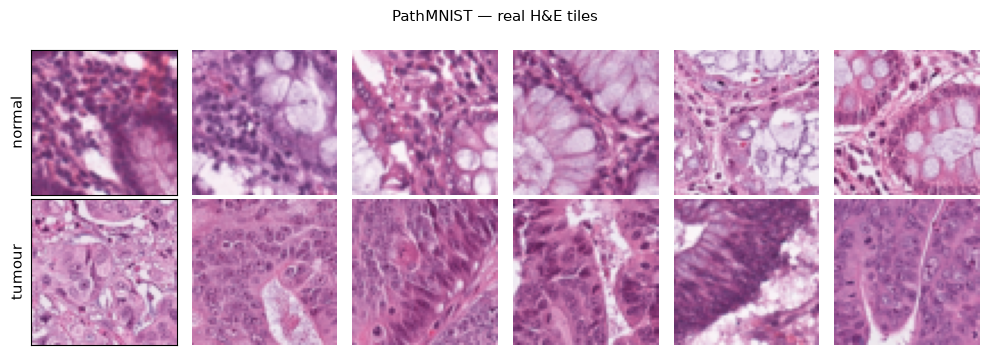

In [4]:
fig, axes = plt.subplots(2, 6, figsize=(10, 3.6))
for r, c in enumerate((0, 1)):
    ci = np.where(ytr_s == c)[0][:6]
    for k, j in enumerate(ci):
        axes[r, k].imshow(xtr_s[j]); axes[r, k].axis("off")
    axes[r, 0].axis("on"); axes[r, 0].set_xticks([]); axes[r, 0].set_yticks([])
    axes[r, 0].set_ylabel(class_names[c], fontsize=11)
plt.suptitle("PathMNIST — real H&E tiles", fontsize=11); plt.tight_layout()
savefig("00_tiles.png"); plt.show()

## 2 · Preprocessing, dataset and helpers
ImageNet normalisation for the pretrained backbone; a `[0,1]` copy is kept for display. The dataset can inject an artifact into one class (`artifact_label`) — used only in Part C.

In [5]:
from torch.utils.data import Dataset, DataLoader
from monai.transforms import Compose, EnsureChannelFirst, ScaleIntensity, Resize, EnsureType

IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
IMAGENET_STD  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

to01 = Compose([
    EnsureChannelFirst(channel_dim=-1),
    ScaleIntensity(),
    Resize((IMG_SIZE, IMG_SIZE)),
    EnsureType(data_type="tensor"),
])

def normalize(x01):
    return (x01 - IMAGENET_MEAN) / IMAGENET_STD   # works for (3,H,W) and (B,3,H,W)

class TileDataset(Dataset):
    def __init__(self, imgs, labels, artifact_label=None):
        self.imgs, self.labels, self.artifact_label = imgs, labels, artifact_label
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, i):
        x01 = to01(self.imgs[i])
        if self.artifact_label is not None and self.labels[i] == self.artifact_label:
            x01 = add_artifact(x01)          # defined in Part C
        return normalize(x01), int(self.labels[i])

def make_loaders(artifact_label=None, bs=32):
    tr = DataLoader(TileDataset(xtr_s, ytr_s, artifact_label), batch_size=bs, shuffle=True)
    va = DataLoader(TileDataset(xva_s, yva_s, artifact_label), batch_size=64)
    return tr, va

# whole test set as one [0,1] tensor -> fast batched tests later
X_TEST01 = torch.stack([to01(x) for x in xte_s]).float()
TUM = np.where(yte_s == 1)[0].tolist(); NOR = np.where(yte_s == 0)[0].tolist()
print("test tensor:", tuple(X_TEST01.shape), "| tumour", len(TUM), "| normal", len(NOR))

def predict01(net, X01, bs=64):
    net.eval(); out = []
    with torch.no_grad():
        for i in range(0, len(X01), bs):
            out.append(net(normalize(X01[i:i+bs]).to(device)).argmax(1).cpu())
    return torch.cat(out).numpy()

test tensor: (600, 3, 128, 128) | tumour 300 | normal 300


In [6]:
def build_densenet(pretrained):
    return DenseNet121(spatial_dims=2, in_channels=3, out_channels=2,
                       pretrained=pretrained).to(device)

TARGET_LAYER = "class_layers.relu"   # last spatial feature map before global pooling

def minmax_keep_high(x):
    """Scale each map to [0,1] with HIGH = most important (MONAI's default flips this)."""
    flat = x.flatten(start_dim=1)
    lo = flat.min(dim=1)[0].view(-1, *([1] * (x.dim() - 1)))
    hi = flat.max(dim=1)[0].view(-1, *([1] * (x.dim() - 1)))
    return (x - lo) / (hi - lo + 1e-8)

def make_cam(net):
    return GradCAM(nn_module=net, target_layers=TARGET_LAYER, postprocessing=minmax_keep_high)

def run_epoch(net, loader, opt=None):
    train = opt is not None
    net.train() if train else net.eval()
    crit = nn.CrossEntropyLoss(); tot = cor = 0; ls = 0.0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = net(x); loss = crit(out, y)
            if train: opt.zero_grad(); loss.backward(); opt.step()
            ls += loss.item() * x.size(0); cor += (out.argmax(1) == y).sum().item(); tot += x.size(0)
    return ls / tot, cor / tot

def train(net, tr_loader, va_loader, epochs=3, lr=1e-4):
    opt = torch.optim.Adam(net.parameters(), lr=lr)
    for ep in range(1, epochs + 1):
        _, tra = run_epoch(net, tr_loader, opt)
        _, vaa = run_epoch(net, va_loader)
        print(f"  epoch {ep}: train acc {tra:.3f} | val acc {vaa:.3f}")
    return net

def evaluate(net, imgs, labels, artifact_label=None):
    net.eval(); preds = []
    loader = DataLoader(TileDataset(imgs, labels, artifact_label), batch_size=64)
    with torch.no_grad():
        for x, _ in loader:
            preds.append(net(x.to(device)).argmax(1).cpu().numpy())
    preds = np.concatenate(preds)
    return preds, float((preds == labels).mean())

# ---- saliency tools (Grad-CAM + hand-built occlusion) and measurement helpers ----
def gradcam_map(cam_obj, x01, class_idx):
    xin = normalize(x01).unsqueeze(0).to(device)
    return cam_obj(x=xin, class_idx=class_idx).squeeze().detach().cpu().numpy()

def occlusion_map(net, x01, target, patch=20, stride=16, baseline=0.0):
    """Grey-out a sliding patch; heat = drop in target-class probability (batched)."""
    net.eval()
    xin = normalize(x01).unsqueeze(0).to(device)
    coords = [(i, j) for i in range(0, IMG_SIZE - patch + 1, stride)
                     for j in range(0, IMG_SIZE - patch + 1, stride)]
    batch = xin.repeat(len(coords), 1, 1, 1)
    for k, (i, j) in enumerate(coords):
        batch[k, :, i:i+patch, j:j+patch] = baseline
    with torch.no_grad():
        base = Fnn.softmax(net(xin), 1)[0, target].item()
        p = Fnn.softmax(net(batch), 1)[:, target].cpu().numpy()
    heat = np.zeros((IMG_SIZE, IMG_SIZE)); cnt = np.zeros((IMG_SIZE, IMG_SIZE))
    for k, (i, j) in enumerate(coords):
        heat[i:i+patch, j:j+patch] += base - p[k]; cnt[i:i+patch, j:j+patch] += 1
    return heat / np.maximum(cnt, 1)

def evidence_share(m, mask):
    """Fraction of a map's positive evidence that falls inside mask."""
    m = np.clip(m, 0, None)
    return float(m[mask].sum() / (m.sum() + 1e-8))

def map_corr(a, b):
    a, b = np.clip(a, 0, None).ravel(), np.clip(b, 0, None).ravel()
    if a.std() < 1e-8 or b.std() < 1e-8: return float("nan")
    return float(np.corrcoef(a, b)[0, 1])

BORDER = 10
BORDER_MASK = np.ones((IMG_SIZE, IMG_SIZE), bool)
BORDER_MASK[BORDER:-BORDER, BORDER:-BORDER] = False
def background_mask(x01):
    return (x01.mean(0) > 0.85).numpy()      # near-white = glass / lumen, no tissue

---
# Part A — Train a clean model *(execution)*
Fine-tune an ImageNet-pretrained DenseNet121 on the clean tumour-vs-normal tiles (600 train / 400 val / 600 test, 3 epochs, Adam lr 1e-4). This model is the **baseline** now and the **clean control** in Part D.

Part A — fine-tuning pretrained DenseNet121 on CLEAN data:
  epoch 1: train acc 0.847 | val acc 0.955
  epoch 2: train acc 0.987 | val acc 0.960
  epoch 3: train acc 1.000 | val acc 0.970

CLEAN model  | validation accuracy: 0.970 | test accuracy: 0.950
             | test sensitivity (tumour recall): 0.937 | specificity: 0.963


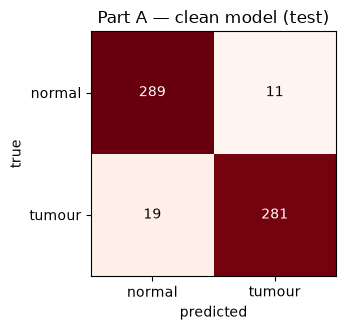

In [7]:
EPOCHS = 3
set_determinism(seed=SEED)
tr_loader, va_loader = make_loaders()
print("Part A — fine-tuning pretrained DenseNet121 on CLEAN data:")
model = train(build_densenet(True), tr_loader, va_loader, epochs=EPOCHS)

from sklearn.metrics import confusion_matrix
_, val_acc  = evaluate(model, xva_s, yva_s)
test_pred, test_acc = evaluate(model, xte_s, yte_s)
tn, fp, fn, tp = confusion_matrix(yte_s, test_pred).ravel()
sens, spec = tp / (tp + fn), tn / (tn + fp)
RESULTS.update(clean_val_acc=val_acc, clean_test_acc=test_acc,
               clean_test_sensitivity=sens, clean_test_specificity=spec)

print(f"\nCLEAN model  | validation accuracy: {val_acc:.3f} | test accuracy: {test_acc:.3f}")
print(f"             | test sensitivity (tumour recall): {sens:.3f} | specificity: {spec:.3f}")

cm = confusion_matrix(yte_s, test_pred)
fig, ax = plt.subplots(figsize=(3.8, 3.4)); ax.imshow(cm, cmap="Reds")
ax.set_xticks([0, 1]); ax.set_xticklabels(class_names); ax.set_yticks([0, 1]); ax.set_yticklabels(class_names)
ax.set_xlabel("predicted"); ax.set_ylabel("true")
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max()/2 else "black")
plt.title("Part A — clean model (test)"); plt.tight_layout(); savefig("A_confusion_clean.png"); plt.show()

---
# Part B — Probe the clean model *(execution + interpretation)*
Grad-CAM and occlusion on 4 tumour and 4 normal test tiles, then the five-point skeptic's checklist — **measured, not eyeballed**:

1. **Plausible morphology?** share of evidence on the tile border / on blank background vs. the area those regions cover
2. **Moves with the target class?** correlation between the class-0 and class-1 Grad-CAM maps (low = it moves)
3. **Occlusion agrees?** correlation between Grad-CAM and occlusion maps
4. **Survives a different stain/scanner?** test accuracy after a simulated stain/colour shift
5. **Clean control?** this model *is* the control — tested against the artifact in Part D

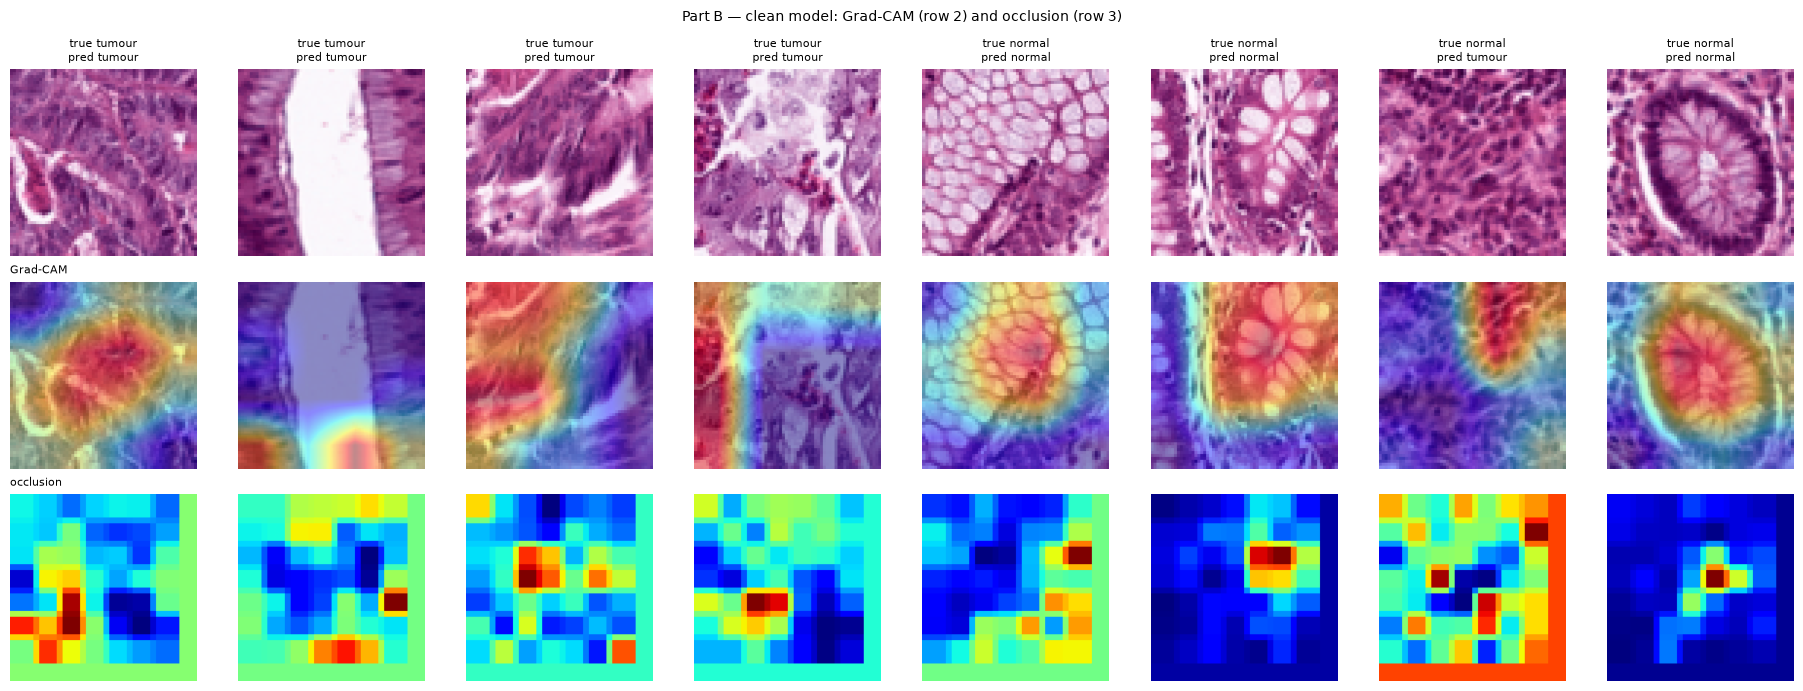

 tile    true    pred | border share | bg area bg share | GC~occ r | class-switch r
    0  tumour  tumour |          21% |      4%       4% |     0.24 |            nan
    1  tumour  tumour |          40% |     39%      36% |     0.17 |          -0.46
    3  tumour  tumour |          27% |      8%       8% |     0.08 |          -0.46
    5  tumour  tumour |          41% |     19%      13% |     0.04 |          -0.54
    2  normal  normal |          18% |     17%      18% |    -0.04 |          -0.38
    4  normal  normal |          21% |     18%      21% |     0.64 |            nan
    7  normal  tumour |          29% |      1%       1% |     0.07 |          -0.73
    8  normal  normal |          20% |      5%       5% |     0.56 |            nan

(border band covers 29% of the tile — a share well above that would be a warning)


In [8]:
cam = make_cam(model)
idxs = list(TUM[:4]) + list(NOR[:4])
rows = []
fig, ax = plt.subplots(3, len(idxs), figsize=(2.3 * len(idxs), 7))
for col, j in enumerate(idxs):
    x01 = X_TEST01[j]
    pr = int(predict01(model, x01.unsqueeze(0))[0])
    g = gradcam_map(cam, x01, pr)
    o = occlusion_map(model, x01, pr)
    g_other = gradcam_map(cam, x01, 1 - pr)
    bg = background_mask(x01)
    rows.append(dict(tile=int(j), true=class_names[yte_s[j]], pred=class_names[pr],
                     border_share=evidence_share(g, BORDER_MASK),
                     bg_area=float(bg.mean()), bg_share=evidence_share(g, bg) if bg.any() else 0.0,
                     gc_vs_occ=map_corr(g, o), class_switch_corr=map_corr(g, g_other)))
    disp = x01.permute(1, 2, 0).numpy()
    ax[0, col].imshow(disp); ax[0, col].set_title(f"true {class_names[yte_s[j]]}\npred {class_names[pr]}", fontsize=8)
    ax[1, col].imshow(disp); ax[1, col].imshow(g, cmap="jet", alpha=0.45, vmin=0, vmax=1)
    ax[2, col].imshow(o, cmap="jet")
    for r in range(3): ax[r, col].axis("off")
ax[1, 0].set_title("Grad-CAM", fontsize=8, loc="left"); ax[2, 0].set_title("occlusion", fontsize=8, loc="left")
plt.suptitle("Part B — clean model: Grad-CAM (row 2) and occlusion (row 3)", fontsize=10)
plt.tight_layout(); savefig("B_clean_gradcam_occlusion.png"); plt.show()

print(f"{'tile':>5} {'true':>7} {'pred':>7} | {'border share':>12} | {'bg area':>7} {'bg share':>8} | {'GC~occ r':>8} | {'class-switch r':>14}")
for r in rows:
    print(f"{r['tile']:>5} {r['true']:>7} {r['pred']:>7} | {r['border_share']:>12.0%} | {r['bg_area']:>7.0%} {r['bg_share']:>8.0%} | {r['gc_vs_occ']:>8.2f} | {r['class_switch_corr']:>14.2f}")
print(f"\n(border band covers {BORDER_MASK.mean():.0%} of the tile — a share well above that would be a warning)")

RESULTS.update(
    B_mean_border_share=float(np.mean([r["border_share"] for r in rows])),
    B_border_area=float(BORDER_MASK.mean()),
    B_mean_gc_vs_occ_corr=float(np.nanmean([r["gc_vs_occ"] for r in rows])),
    B_mean_class_switch_corr=float(np.nanmean([r["class_switch_corr"] for r in rows])),
)

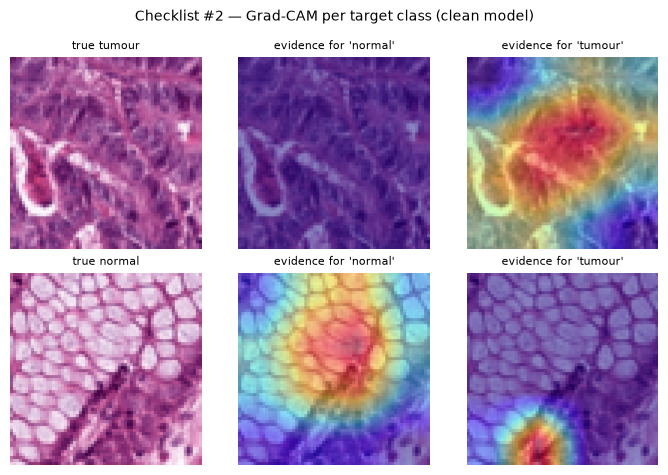

In [9]:
# Checklist #2 visual: does the Grad-CAM map move when we ask about the OTHER class?
fig, ax = plt.subplots(2, 3, figsize=(7, 4.8))
for r, j in enumerate([TUM[0], NOR[0]]):
    x01 = X_TEST01[j]; disp = x01.permute(1, 2, 0).numpy()
    ax[r, 0].imshow(disp); ax[r, 0].set_title(f"true {class_names[yte_s[j]]}", fontsize=8)
    for c in (0, 1):
        ax[r, c + 1].imshow(disp); ax[r, c + 1].imshow(gradcam_map(cam, x01, c), cmap="jet", alpha=0.45, vmin=0, vmax=1)
        ax[r, c + 1].set_title(f"evidence for '{class_names[c]}'", fontsize=8)
    for a in ax[r]: a.axis("off")
plt.suptitle("Checklist #2 — Grad-CAM per target class (clean model)", fontsize=10)
plt.tight_layout(); savefig("B_class_switch.png"); plt.show()

clean model test accuracy — original stain: 0.950 | mild shift: 0.938 | strong shift: 0.952


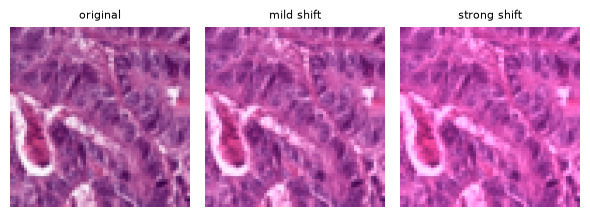

In [10]:
# Checklist #4: would it survive a different stain / scanner? Simulate an H&E colour shift on the TEST set.
def stain_shift(X01, gains=(1.08, 0.92, 1.05), offset=0.03):
    return (X01 * torch.tensor(gains).view(1, 3, 1, 1) + offset).clamp(0, 1)

acc_orig   = float((predict01(model, X_TEST01) == yte_s).mean())
acc_mild   = float((predict01(model, stain_shift(X_TEST01)) == yte_s).mean())
acc_strong = float((predict01(model, stain_shift(X_TEST01, (1.18, 0.82, 1.10), 0.06)) == yte_s).mean())
RESULTS.update(B_test_acc_original_stain=acc_orig, B_test_acc_mild_stain_shift=acc_mild,
               B_test_acc_strong_stain_shift=acc_strong)
print(f"clean model test accuracy — original stain: {acc_orig:.3f} | mild shift: {acc_mild:.3f} | strong shift: {acc_strong:.3f}")

fig, ax = plt.subplots(1, 3, figsize=(6, 2.3)); j = TUM[0]
for a, (X, t) in zip(ax, [(X_TEST01[j:j+1], "original"), (stain_shift(X_TEST01[j:j+1]), "mild shift"),
                          (stain_shift(X_TEST01[j:j+1], (1.18, 0.82, 1.10), 0.06), "strong shift")]):
    a.imshow(X[0].permute(1, 2, 0).numpy()); a.set_title(t, fontsize=8); a.axis("off")
plt.tight_layout(); savefig("B_stain_shift.png"); plt.show()

In [11]:
# Part B — the checklist, scored from the numbers above
R = RESULTS
print("SKEPTIC'S CHECKLIST — clean model")
print(f"1. plausible morphology : border share {R['B_mean_border_share']:.0%} vs border area {R['B_border_area']:.0%}",
      "-> OK" if R['B_mean_border_share'] < 1.5 * R['B_border_area'] else "-> WARNING: evidence piles up at the border")
print(f"2. moves with class     : mean class-0 vs class-1 map correlation {R['B_mean_class_switch_corr']:.2f}",
      "-> OK (maps differ)" if R['B_mean_class_switch_corr'] < 0.5 else "-> WARNING: same map for both classes")
print(f"3. occlusion agrees     : mean Grad-CAM~occlusion correlation {R['B_mean_gc_vs_occ_corr']:.2f}",
      "-> agree" if R['B_mean_gc_vs_occ_corr'] > 0.2 else "-> weak agreement: don't trust either map alone")
print(f"4. survives stain shift : {R['B_test_acc_original_stain']:.3f} -> {R['B_test_acc_mild_stain_shift']:.3f} (mild) -> {R['B_test_acc_strong_stain_shift']:.3f} (strong)")
print("5. clean control       : this model is the control — see Part D")

SKEPTIC'S CHECKLIST — clean model
1. plausible morphology : border share 27% vs border area 29% -> OK
2. moves with class     : mean class-0 vs class-1 map correlation -0.51 -> OK (maps differ)
3. occlusion agrees     : mean Grad-CAM~occlusion correlation 0.22 -> agree
4. survives stain shift : 0.950 -> 0.938 (mild) -> 0.952 (strong)
5. clean control       : this model is the control — see Part D


### Part B — interpretation
*(Written after running — see the checklist printout above and the figures in `figures/B_*.png`.)*

▶ **TO FILL from my run:** Does the clean model key on tissue (nuclei, glands, epithelial architecture) or on something it shouldn't (border, blank glass, a lumen)? Do Grad-CAM and occlusion agree? How much accuracy is lost under a stain shift, and what does that say about site transfer?

---
# Part C — My own confounder: a scanner / slide-label tag *(execution)*

**The artifact.** A small off-white label with dark barcode bars burned into the **top-left corner** of every **tumour** tile, in training *and* validation (≈3% of the tile).

**Why it is a realistic batch effect.** Whole-slide scanners and lab information systems stamp slide labels, barcodes and site watermarks into digital images, and each site's scanner leaves its own signature. If the tumour cases in a training set come mostly from one referral centre (whose scanner/label pipeline leaves a mark) and the normal tissue comes from elsewhere, *the tag correlates with the diagnosis* — the same mechanism behind documented site-specific signatures in TCGA histology that let models recognise the submitting site rather than the biology. Unlike Notebook 2's blue ink circling a tumour, this one has nothing to do with a human looking at the tissue — it is pure acquisition pipeline.

**Why this size.** Small and corner-placed so a clean model should plausibly ignore it, but high-contrast and perfectly consistent so a confounded model *could* latch on. If the clean control reacts strongly too, the tag proves nothing — I shrink it (`TAG_H`, `TAG_W`) or lower the contrast and retrain (see the iteration note in Part D).

tag covers 3.1% of the tile


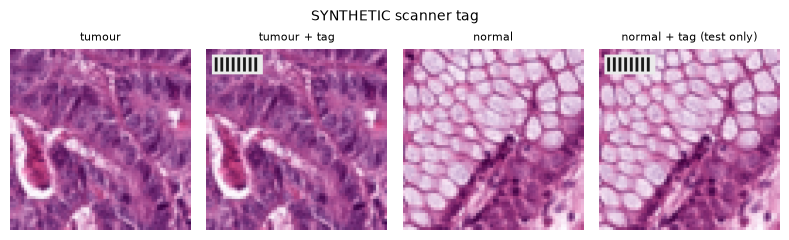

In [12]:
ARTIFACT_LABEL = 1          # tumour
TAG_R0, TAG_C0 = 4, 4       # top-left corner
TAG_H, TAG_W   = 14, 36     # tag size in pixels (≈3% of a 128 px tile)
TAG_LEVEL, BAR_LEVEL = 0.92, 0.10   # off-white label, dark barcode bars

TAG_MASK = np.zeros((IMG_SIZE, IMG_SIZE), bool)
TAG_MASK[TAG_R0:TAG_R0 + TAG_H, TAG_C0:TAG_C0 + TAG_W] = True

def add_scanner_tag(x01):
    """x01: (3,H,W) or (B,3,H,W) in [0,1]. Burn a small barcode label into the corner."""
    x = x01.clone()
    r0, r1, c0, c1 = TAG_R0, TAG_R0 + TAG_H, TAG_C0, TAG_C0 + TAG_W
    x[..., r0:r1, c0:c1] = TAG_LEVEL
    for k in range(c0 + 2, c1 - 2, 4):
        x[..., r0 + 2:r1 - 2, k:k + 2] = BAR_LEVEL
    return x

add_artifact = add_scanner_tag     # the dataset injects this into ARTIFACT_LABEL tiles
print(f"tag covers {TAG_MASK.mean():.1%} of the tile")

fig, ax = plt.subplots(1, 4, figsize=(8, 2.4))
for a, (x, t) in zip(ax, [(X_TEST01[TUM[0]], "tumour"), (add_scanner_tag(X_TEST01[TUM[0]]), "tumour + tag"),
                          (X_TEST01[NOR[0]], "normal"), (add_scanner_tag(X_TEST01[NOR[0]]), "normal + tag (test only)")]):
    a.imshow(x.permute(1, 2, 0).numpy()); a.set_title(t, fontsize=8); a.axis("off")
plt.suptitle("SYNTHETIC scanner tag", fontsize=10); plt.tight_layout(); savefig("C_scanner_tag.png"); plt.show()

In [13]:
# Retrain the SAME transfer setup — but every tumour tile (train AND val) now carries the tag
set_determinism(seed=SEED)
tr_cf, va_cf = make_loaders(artifact_label=ARTIFACT_LABEL)
print("Part C — training CONFOUNDED model (tumour tiles carry the scanner tag):")
model_cf = train(build_densenet(True), tr_cf, va_cf, epochs=EPOCHS)

_, cf_val_tagged = evaluate(model_cf, xva_s, yva_s, artifact_label=ARTIFACT_LABEL)
cf_test_clean = float((predict01(model_cf, X_TEST01) == yte_s).mean())
RESULTS.update(cf_val_acc_tagged=cf_val_tagged, cf_test_acc_no_tag=cf_test_clean)
print(f"\nCONFOUNDED model | validation accuracy (tagged, as it would be 'reported'): {cf_val_tagged:.3f}")
print(f"                 | test accuracy on untagged tiles (a new site without the tag): {cf_test_clean:.3f}")
print(f"CLEAN model      | validation accuracy: {RESULTS['clean_val_acc']:.3f} | test: {RESULTS['clean_test_acc']:.3f}")

Part C — training CONFOUNDED model (tumour tiles carry the scanner tag):
  epoch 1: train acc 0.893 | val acc 0.993
  epoch 2: train acc 1.000 | val acc 0.998
  epoch 3: train acc 1.000 | val acc 1.000

CONFOUNDED model | validation accuracy (tagged, as it would be 'reported'): 1.000
                 | test accuracy on untagged tiles (a new site without the tag): 0.748
CLEAN model      | validation accuracy: 0.970 | test: 0.950


---
# Part D — Prove whether it was learned *(execution + interpretation)*
Every test is run on **both** models. The confounded model alone proves nothing; **the gap between it and the clean control is the proof.**

1. **Grad-CAM + occlusion** on tagged tiles — where does the heat land? (measured as share of evidence on the tag)
2. **Reliance test** — tumour recall with the tag vs. without it
3. **Flip rate** — add the tag to normal tiles; how many are called tumour?
4. **Clean control** — does the Part A model react the same way?

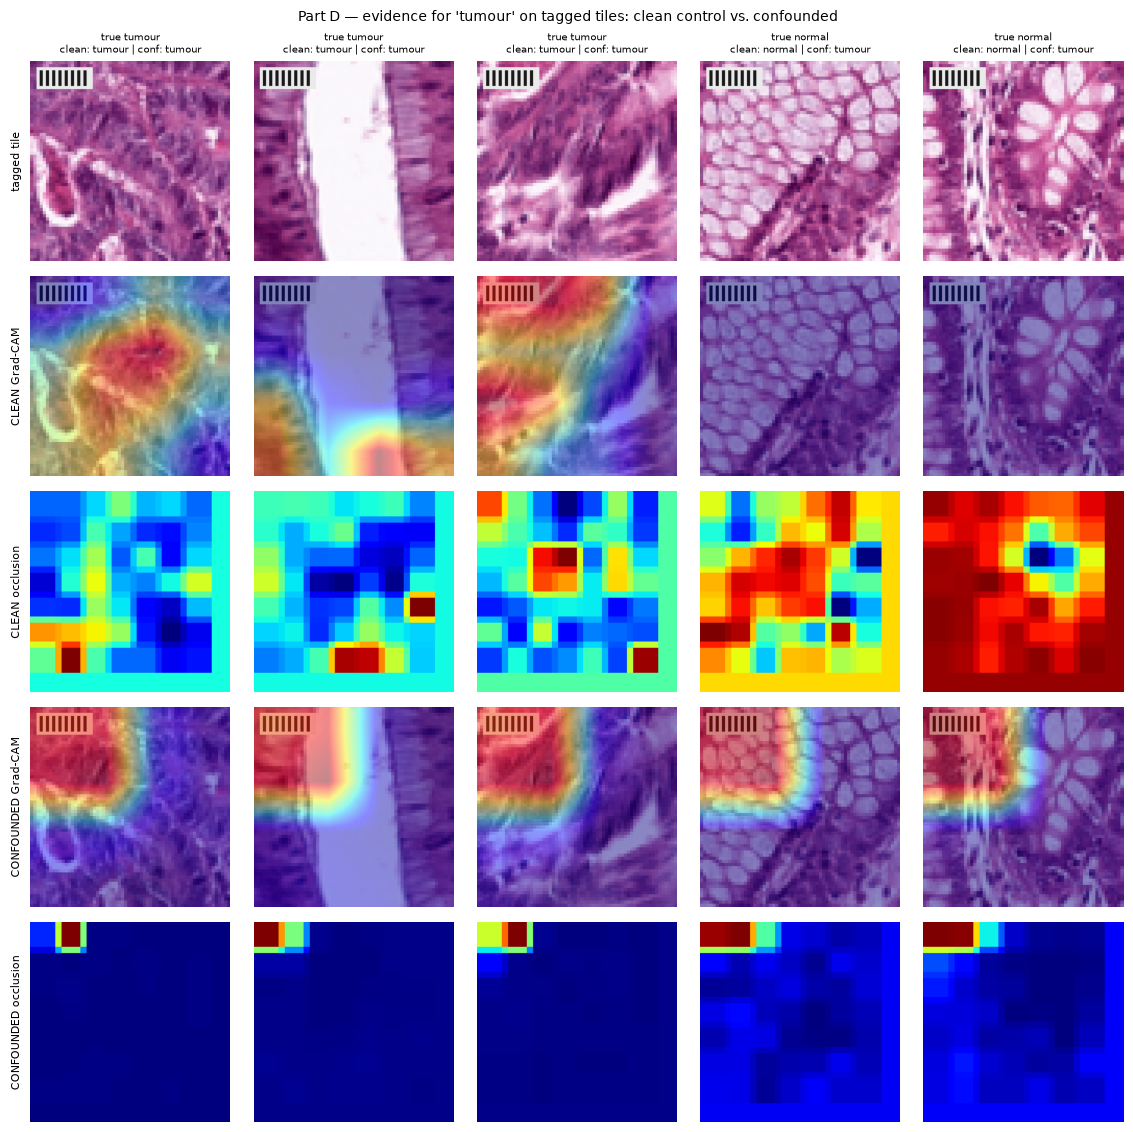

In [14]:
# D1 — heatmaps on tagged tiles, both models, evidence for "tumour"
cam_cf = make_cam(model_cf)
show = [TUM[0], TUM[1], TUM[2], NOR[0], NOR[1]]
fig, ax = plt.subplots(5, len(show), figsize=(2.3 * len(show), 11.5))
labels = ["tagged tile", "CLEAN Grad-CAM", "CLEAN occlusion", "CONFOUNDED Grad-CAM", "CONFOUNDED occlusion"]
for col, j in enumerate(show):
    x01 = add_scanner_tag(X_TEST01[j]); disp = x01.permute(1, 2, 0).numpy()
    p_cl = class_names[int(predict01(model, x01.unsqueeze(0))[0])]
    p_cf = class_names[int(predict01(model_cf, x01.unsqueeze(0))[0])]
    ax[0, col].imshow(disp); ax[0, col].set_title(f"true {class_names[yte_s[j]]}\nclean: {p_cl} | conf: {p_cf}", fontsize=7)
    for r, (net, cobj) in enumerate([(model, cam), (model_cf, cam_cf)]):
        g = gradcam_map(cobj, x01, 1); o = occlusion_map(net, x01, 1)
        ax[1 + 2*r, col].imshow(disp); ax[1 + 2*r, col].imshow(g, cmap="jet", alpha=0.45, vmin=0, vmax=1)
        ax[2 + 2*r, col].imshow(o, cmap="jet")
    for r in range(5): ax[r, col].axis("off")
for r in range(5): ax[r, 0].text(-6, IMG_SIZE / 2, labels[r], rotation=90, va="center", ha="right", fontsize=8)
plt.suptitle("Part D — evidence for 'tumour' on tagged tiles: clean control vs. confounded", fontsize=10)
plt.tight_layout(); savefig("D_heatmaps_both_models.png"); plt.show()

In [15]:
# D1 (measured) — average share of evidence on the tag over 10 tagged tumour tiles
N_TILES = 10
tag_area = float(TAG_MASK.mean())
shares = {}
for name, net, cobj in [("clean", model, cam), ("confounded", model_cf, cam_cf)]:
    gs, os_ = [], []
    for j in TUM[:N_TILES]:
        x01 = add_scanner_tag(X_TEST01[j])
        gs.append(evidence_share(gradcam_map(cobj, x01, 1), TAG_MASK))
        os_.append(evidence_share(occlusion_map(net, x01, 1), TAG_MASK))
    shares[name] = (float(np.mean(gs)), float(np.mean(os_)))
RESULTS.update(tag_area=tag_area,
               clean_gradcam_share_on_tag=shares["clean"][0], clean_occlusion_share_on_tag=shares["clean"][1],
               cf_gradcam_share_on_tag=shares["confounded"][0], cf_occlusion_share_on_tag=shares["confounded"][1])
print(f"tag covers {tag_area:.1%} of the tile (a map with no preference would put ~{tag_area:.1%} of its evidence there)")
print(f"{'':12} {'Grad-CAM on tag':>16} {'occlusion on tag':>17}")
for k, (g, o) in shares.items():
    print(f"{k:12} {g:>16.0%} {o:>17.0%}")

tag covers 3.1% of the tile (a map with no preference would put ~3.1% of its evidence there)
              Grad-CAM on tag  occlusion on tag
clean                      1%                2%
confounded                10%               62%


In [16]:
# D2 — reliance test: tumour recall WITH the tag vs WITHOUT it
def tumour_recall(net, with_tag):
    X = X_TEST01[TUM]
    if with_tag: X = add_scanner_tag(X)
    return float((predict01(net, X) == 1).mean())

# D3 — flip rate: add the tag to every NORMAL test tile (baseline = normals called tumour with no tag)
def normal_called_tumour(net, with_tag):
    X = X_TEST01[NOR]
    if with_tag: X = add_scanner_tag(X)
    return float((predict01(net, X) == 1).mean())

for name, net in [("clean", model), ("cf", model_cf)]:
    RESULTS[f"{name}_tumour_recall_with_tag"]    = tumour_recall(net, True)
    RESULTS[f"{name}_tumour_recall_without_tag"] = tumour_recall(net, False)
    RESULTS[f"{name}_normal_fp_no_tag"]          = normal_called_tumour(net, False)
    RESULTS[f"{name}_normal_flip_with_tag"]      = normal_called_tumour(net, True)

R = RESULTS
print(f"normal test tiles: {len(NOR)} | tumour test tiles: {len(TUM)}\n")
print(f"{'':34} {'CLEAN':>8} {'CONFOUNDED':>11}")
print(f"{'tumour recall WITH tag':34} {R['clean_tumour_recall_with_tag']:>8.3f} {R['cf_tumour_recall_with_tag']:>11.3f}")
print(f"{'tumour recall WITHOUT tag':34} {R['clean_tumour_recall_without_tag']:>8.3f} {R['cf_tumour_recall_without_tag']:>11.3f}")
print(f"{'normals called tumour, no tag':34} {R['clean_normal_fp_no_tag']:>8.1%} {R['cf_normal_fp_no_tag']:>11.1%}")
print(f"{'normals called tumour, + tag (flip)':34} {R['clean_normal_flip_with_tag']:>8.1%} {R['cf_normal_flip_with_tag']:>11.1%}")

normal test tiles: 300 | tumour test tiles: 300

                                      CLEAN  CONFOUNDED
tumour recall WITH tag                0.930       1.000
tumour recall WITHOUT tag             0.937       0.497
normals called tumour, no tag          3.7%        0.0%
normals called tumour, + tag (flip)     5.3%       87.3%


In [17]:
# D4 — summary table, saved for the report, and an evidence-based verdict
R = RESULTS
with open(os.path.join(RES_DIR, "module10_results.csv"), "w", newline="") as f:
    w = csv.writer(f); w.writerow(["metric", "value"])
    for k, v in R.items(): w.writerow([k, f"{v:.4f}"])

cf_drop    = R["cf_tumour_recall_with_tag"] - R["cf_tumour_recall_without_tag"]
clean_drop = R["clean_tumour_recall_with_tag"] - R["clean_tumour_recall_without_tag"]
cf_flip    = R["cf_normal_flip_with_tag"] - R["cf_normal_fp_no_tag"]
clean_flip = R["clean_normal_flip_with_tag"] - R["clean_normal_fp_no_tag"]
print("                                 CLEAN   CONFOUNDED")
print(f"recall drop when tag removed  : {clean_drop:+.3f}   {cf_drop:+.3f}")
print(f"extra normals flipped by tag  : {clean_flip:+.1%}   {cf_flip:+.1%}")
print(f"occlusion evidence on the tag : {R['clean_occlusion_share_on_tag']:.0%}     {R['cf_occlusion_share_on_tag']:.0%}   (tag area {R['tag_area']:.1%})")
print(f"Grad-CAM evidence on the tag  : {R['clean_gradcam_share_on_tag']:.0%}     {R['cf_gradcam_share_on_tag']:.0%}")

control_ok = clean_flip < 0.20 and abs(clean_drop) < 0.10
learned    = cf_drop > 0.30 and cf_flip > 0.30
print("\nVERDICT:")
if control_ok and learned:
    print("-> The confounded model LEARNED the tag; the clean control largely ignores it. The gap is the proof.")
elif control_ok and not learned:
    print("-> The clean control ignores the tag AND the confounded model does not depend on it: the shortcut was NOT learned.")
    print("   (An honest, creditworthy finding — report it. Optionally iterate: larger / higher-contrast tag.)")
elif not control_ok:
    print("-> The CLEAN model also reacts to the tag, so the flip/recall tests cannot prove learning (like Notebook 2's dark band).")
    print("   ITERATE: make the tag smaller (e.g. TAG_H, TAG_W = 10, 24) or lower contrast (TAG_LEVEL 0.85), re-run Part C/D, report both.")

                                 CLEAN   CONFOUNDED
recall drop when tag removed  : -0.007   +0.503
extra normals flipped by tag  : +1.7%   +87.3%
occlusion evidence on the tag : 2%     62%   (tag area 3.1%)
Grad-CAM evidence on the tag  : 1%     10%

VERDICT:
-> The confounded model LEARNED the tag; the clean control largely ignores it. The gap is the proof.


### Part D — interpretation
▶ **TO FILL from my run:** where the heat lands on tagged tiles for each model; the reliance and flip numbers side by side; whether the clean control ignored the tag; final verdict (learned / not learned) and how I know.

---
# Part E — Report
The 3–4 page write-up (confounder realism, evidence, verdict, deployment & trust) is `BIOT6900_Module10_Report.pdf` in this folder. All numbers it quotes come from `results/module10_results.csv`, and all figures from `figures/`.